<a href="https://colab.research.google.com/github/ajasrotiabe/imgprocessing/blob/main/assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving _ (12).jpeg to _ (12).jpeg


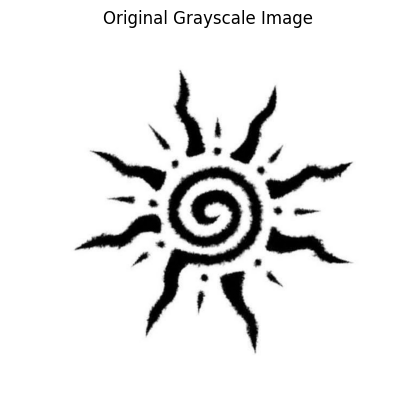

In [1]:

!pip install opencv-python scikit-image -q

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()


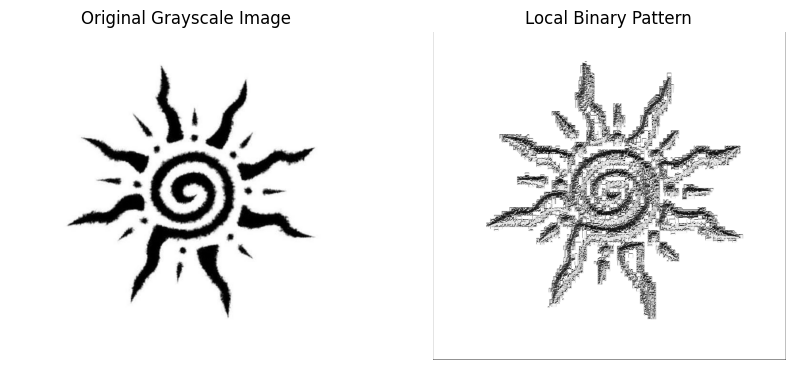

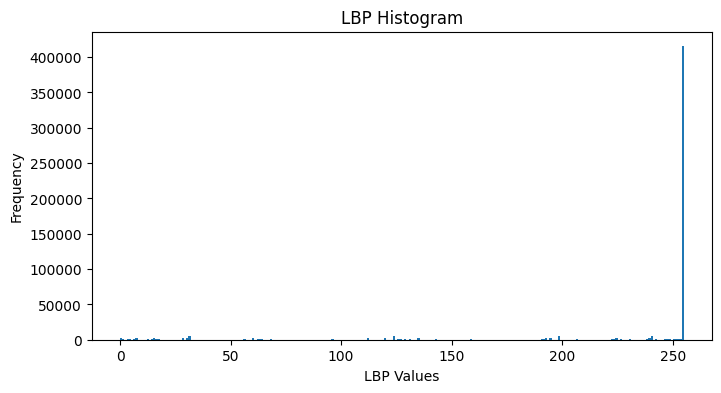

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

# Read grayscale image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# LBP parameters
radius = 1
n_points = 8 * radius

# Apply Local Binary Pattern
lbp = local_binary_pattern(img, n_points, radius, method='default')

# Display original and LBP image
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("Local Binary Pattern")
plt.axis('off')

plt.show()

# Plot LBP histogram
plt.figure(figsize=(8, 4))
plt.hist(lbp.ravel(), bins=256)
plt.title("LBP Histogram")
plt.xlabel("LBP Values")
plt.ylabel("Frequency")
plt.show()


/usr/local/lib/python3.13/dist-packages/scipy/signal/_signaltools.py:1783: RuntimeWarning: divide by zero encountered in divide
  res *= (1 - noise / lVar)
/usr/local/lib/python3.13/dist-packages/scipy/signal/_signaltools.py:1783: RuntimeWarning: invalid value encountered in multiply
  res *= (1 - noise / lVar)


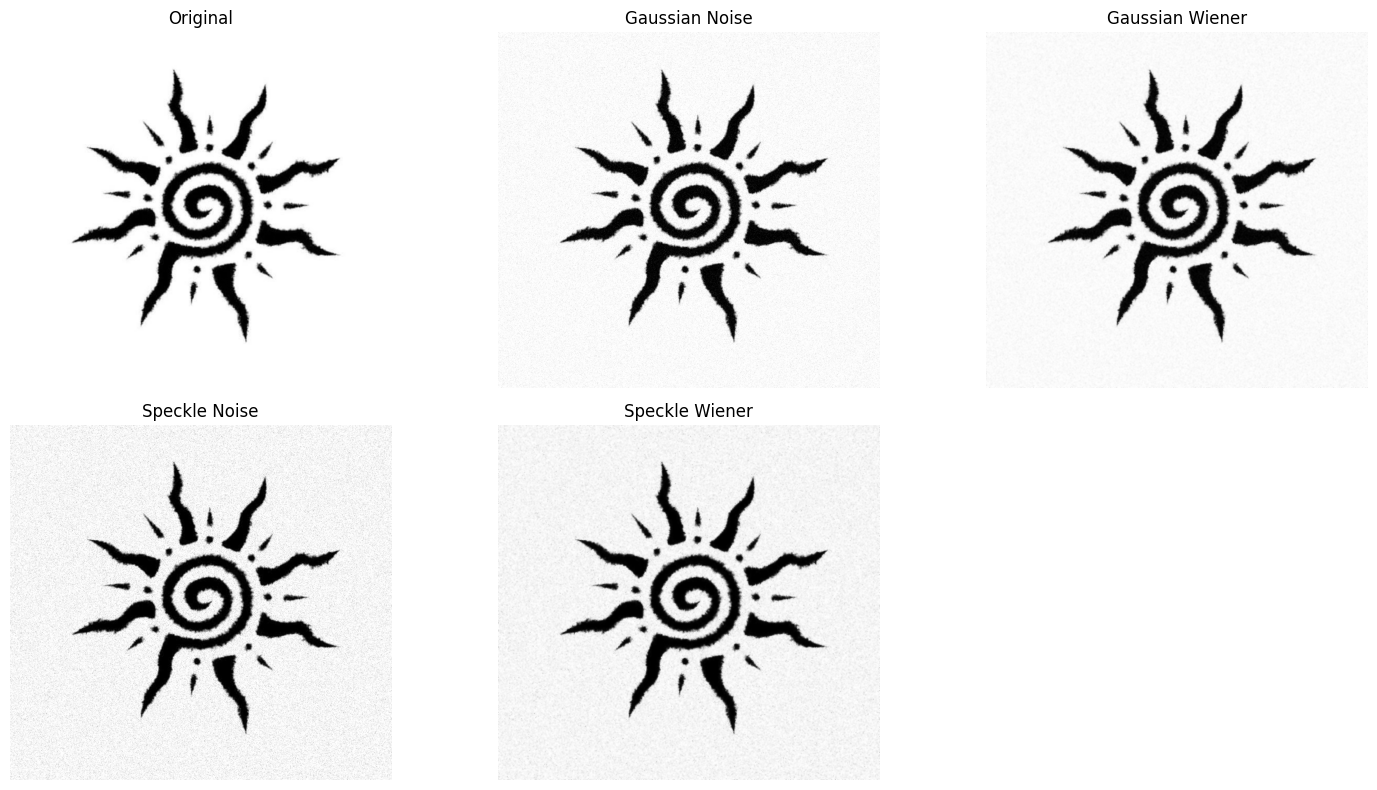

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read grayscale image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Normalize image
img = img.astype(np.float32) / 255.0

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 0.05, img.shape)

# Add Speckle noise
speckle_noise = img + img * np.random.normal(0, 0.1, img.shape)

# Clip values
gaussian_noise = np.clip(gaussian_noise, 0, 1)
speckle_noise = np.clip(speckle_noise, 0, 1)

# Apply Wiener filter (3x3)
gaussian_filtered = wiener(gaussian_noise, (3, 3))
speckle_filtered = wiener(speckle_noise, (3, 3))

# Display results
images = [img, gaussian_noise, gaussian_filtered,
          speckle_noise, speckle_filtered]

titles = ["Original", "Gaussian Noise", "Gaussian Wiener",
          "Speckle Noise", "Speckle Wiener"]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


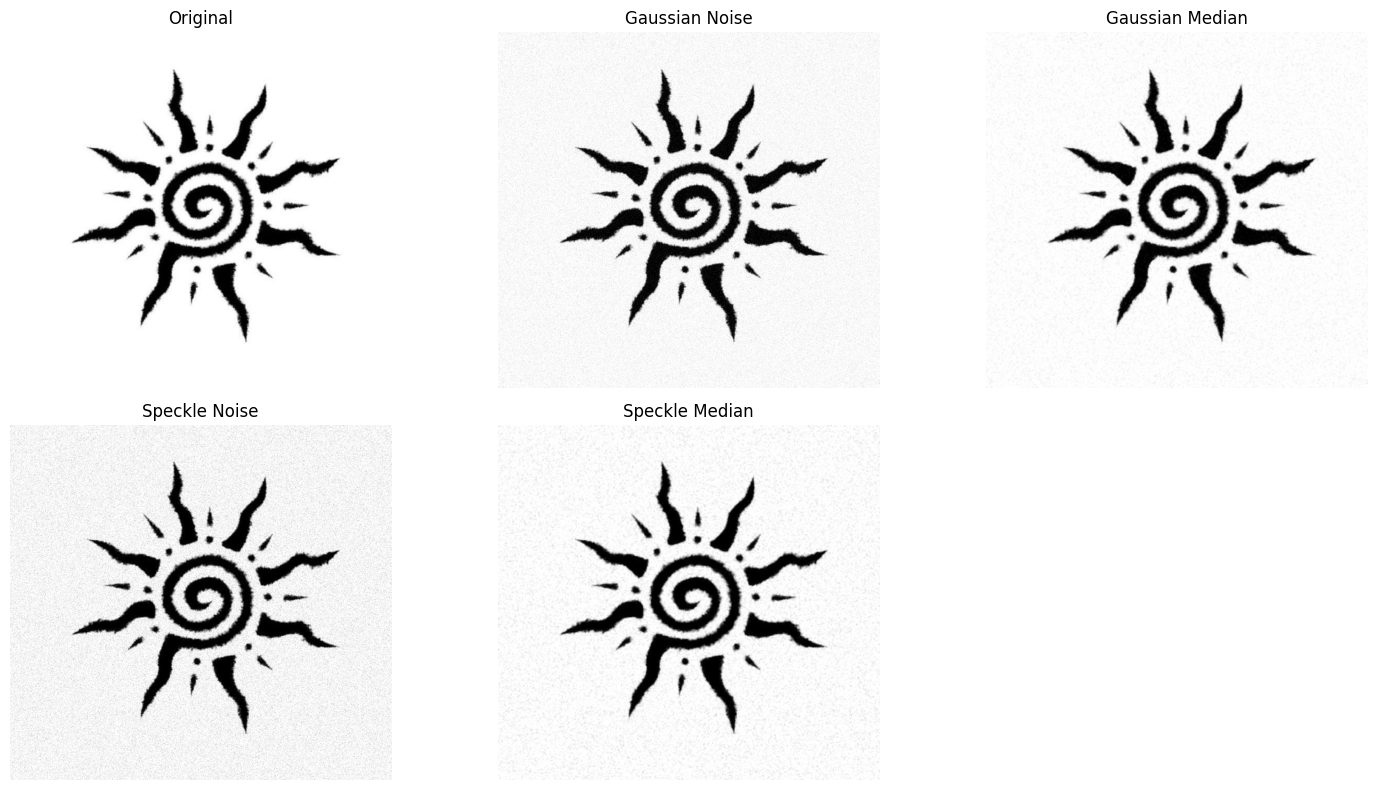

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 15, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 255).astype(np.uint8)

# Add Speckle noise
img_float = img.astype(np.float32)
speckle_noise = img_float + img_float * np.random.normal(0, 0.1, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 255).astype(np.uint8)

# Apply Median Filter (3x3)
gaussian_filtered = cv2.medianBlur(gaussian_noise, 3)
speckle_filtered = cv2.medianBlur(speckle_noise, 3)

# Display results
images = [img, gaussian_noise, gaussian_filtered,
          speckle_noise, speckle_filtered]

titles = ["Original", "Gaussian Noise", "Gaussian Median",
          "Speckle Noise", "Speckle Median"]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


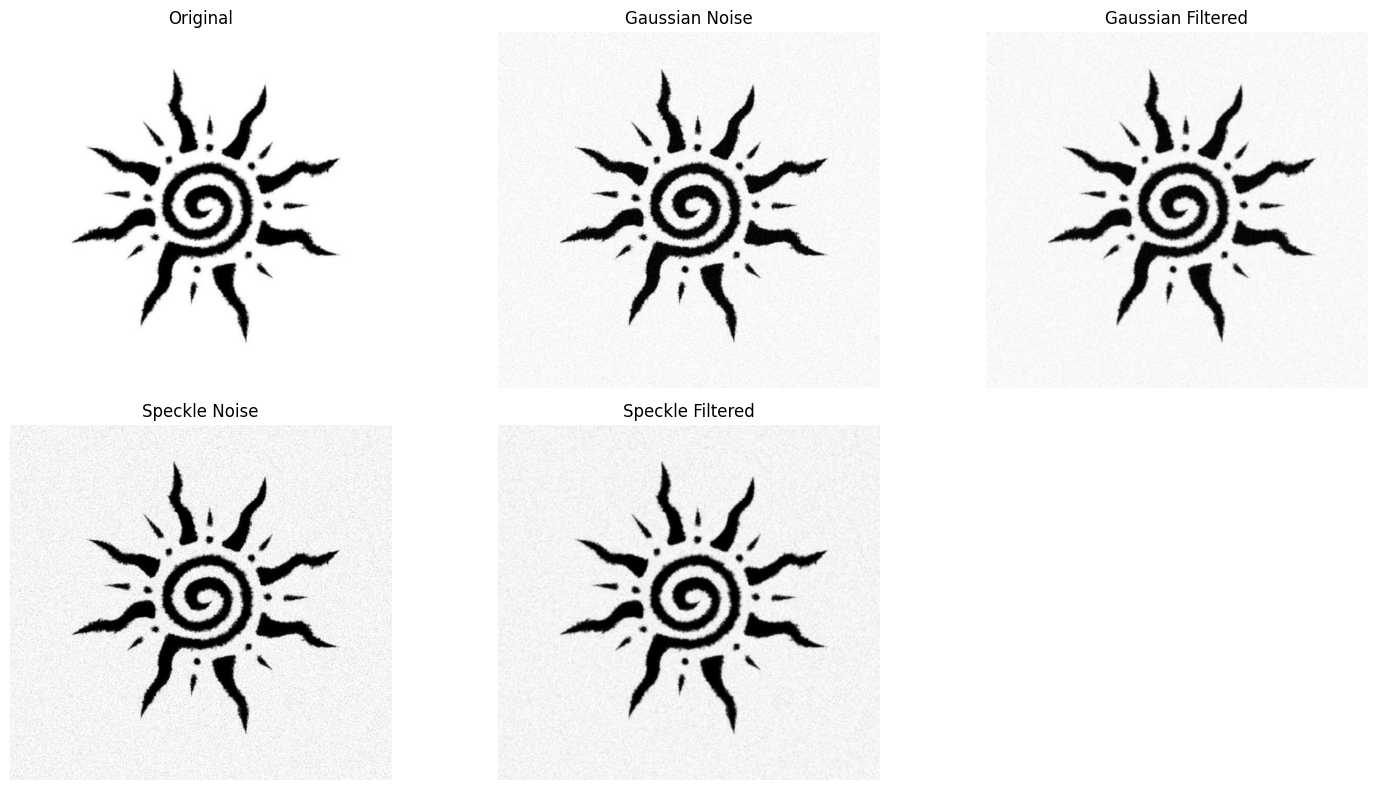

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 15, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 255).astype(np.uint8)

# Add Speckle noise
img_float = img.astype(np.float32)
speckle_noise = img_float + img_float * np.random.normal(0, 0.1, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 255).astype(np.uint8)

# Apply Gaussian Filter (3x3)
gaussian_filtered = cv2.GaussianBlur(gaussian_noise, (3, 3), 0)
speckle_filtered = cv2.GaussianBlur(speckle_noise, (3, 3), 0)

# Display results
images = [img, gaussian_noise, gaussian_filtered,
          speckle_noise, speckle_filtered]

titles = ["Original", "Gaussian Noise", "Gaussian Filtered",
          "Speckle Noise", "Speckle Filtered"]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


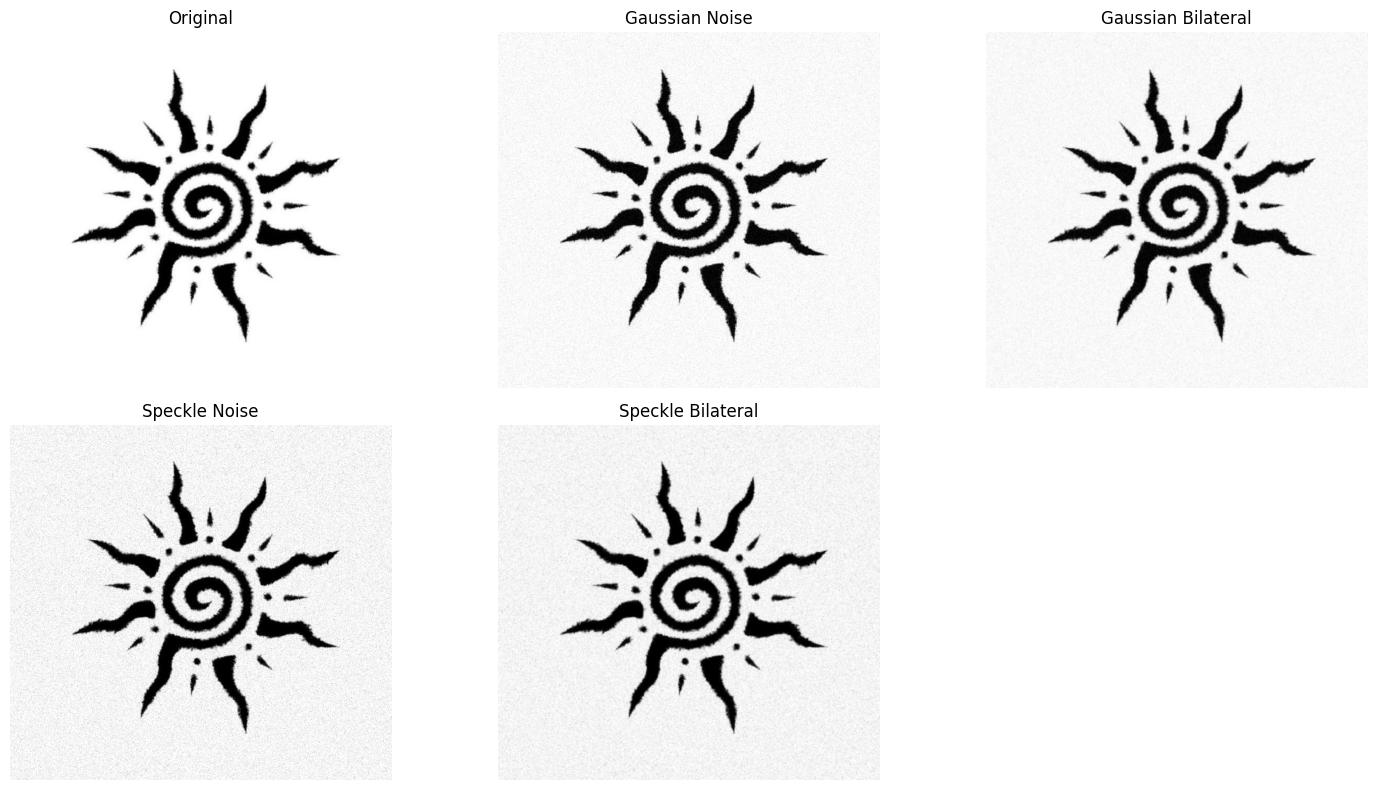

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 15, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 255).astype(np.uint8)

# Add Speckle noise
img_float = img.astype(np.float32)
speckle_noise = img_float + img_float * np.random.normal(0, 0.1, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 255).astype(np.uint8)

# Apply Bilateral Filter
gaussian_filtered = cv2.bilateralFilter(gaussian_noise, 3, 75, 75)
speckle_filtered = cv2.bilateralFilter(speckle_noise, 3, 75, 75)

# Display results
images = [img, gaussian_noise, gaussian_filtered,
          speckle_noise, speckle_filtered]

titles = ["Original", "Gaussian Noise", "Gaussian Bilateral",
          "Speckle Noise", "Speckle Bilateral"]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()
